# Exploratory Data Analysis: Fantasy Football
## CSCI 5502 - Milestone 2

### Objective

This notebook explores historical NFL fantasy football data from
the 2025 season.

Our goals are to:
- Understand the distribution of fantasy points.
- Examine differences across player positions.
- Compare projected and actual fantasy points.
- Investigate weekly performance trends.
- Identify missing values, inconsistencies, and possible outliers.

Missing values will be preserved during the initial exploration.
We will investigate them before deciding whether to remove,
impute, or retain them.

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Project directory
root = Path.cwd().parent

# Load the original dataset
df = pd.read_csv(root / "data" / "final_2025.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (7572, 81)


,Unnamed: 0,player_id,player,position,team,season,week,eventId,date,opponent,...,location,espn,game_id,gameday,gametime,stadium,roof,surface,temp,wind
0,0,4429795,Jahmyr Gibbs,RB,DET,2025,18,401772965,2026-01-04T21:25:00.000+00:00,CHI,...,"Chicago, IL",401772965,2025_18_DET_CHI,2026-01-04,16:25,Soldier Field,outdoors,grass,33.0,4.0
1,1,4429795,Jahmyr Gibbs,RB,DET,2025,17,401772711,2025-12-25T21:30:00.000+00:00,MIN,...,"Minneapolis, MN",401772711,2025_17_DET_MIN,2025-12-25,16:30,U.S. Bank Stadium,dome,sportturf,NaN,NaN
2,2,4429795,Jahmyr Gibbs,RB,DET,2025,16,401772806,2025-12-21T21:25:00.000+00:00,PIT,...,"Detroit, MI",401772806,2025_16_PIT_DET,2025-12-21,16:25,Ford Field,dome,fieldturf,NaN,NaN
3,3,4429795,Jahmyr Gibbs,RB,DET,2025,15,401772909,2025-12-14T21:25:00.000+00:00,LAR,...,"Inglewood, CA",401772909,2025_15_DET_LA,2025-12-14,16:25,SoFi Stadium,dome,matrixturf,NaN,NaN
4,4,4429795,Jahmyr Gibbs,RB,DET,2025,14,401772947,2025-12-05T01:15:00.000+00:00,DAL,...,"Detroit, MI",401772947,2025_14_DAL_DET,2025-12-04,20:15,Ford Field,dome,fieldturf,NaN,NaN


In [19]:
print("Unique players:", df["player_id"].nunique())
print("Unique weeks:", df["week"].nunique())

print("\nRecords by position:")
display(df["position"].value_counts())

print("\nMissing values:")
display(df.isna().sum())

print("\nSummary statistics:")
display(df.describe())

Unique players: 685
Unique weeks: 18

Records by position:


position
WR    2806
RB    1808
TE    1739
QB     676
K      543
Name: count, dtype: int64


Missing values:


Unnamed: 0       0
player_id        0
player           0
position         0
team             0
              ... 
stadium          0
roof             0
surface         27
temp          2633
wind          2633
Length: 81, dtype: int64


Summary statistics:


,Unnamed: 0,player_id,season,week,eventId,rushingAttempts,rushingYards,yardsPerRushAttempt,rushingTouchdowns,longRushing,...,fieldGoalsMade,fieldGoalAttempts,extraPointsMade,extraPointAttempts,opp_def_rank,fantasy_points,projected_points,espn,temp,wind
count,7572.000000,7.572000e+03,7572.0,7572.000000,7.572000e+03,7023.000000,7023.000000,7023.000000,7023.000000,7023.000000,...,543.000000,543.000000,543.000000,543.000000,7572.000000,7572.000000,7281.000000,7.572000e+03,4939.000000,4939.000000
mean,3785.500000,3.967996e+06,2025.0,9.499208,4.017728e+08,2.078172,9.063506,1.350776,0.072619,3.421615,...,1.714549,2.003683,2.228361,2.322284,16.545827,6.526960,6.948332,4.017728e+08,58.703584,7.866572
std,2185.992452,1.012643e+06,0.0,5.293262,8.682401e+01,4.594061,22.735785,3.005645,0.312778,8.022528,...,1.246956,1.323916,1.439867,1.445569,9.213211,7.599769,5.911628,8.682401e+01,18.088415,4.456238
min,0.000000,5.529000e+03,2025.0,1.000000,4.017725e+08,0.000000,-14.000000,-10.000000,0.000000,-10.000000,...,0.000000,0.000000,0.000000,0.000000,1.000000,-3.060000,0.000000,4.017725e+08,8.000000,0.000000
25%,1892.750000,3.917914e+06,2025.0,5.000000,4.017728e+08,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.000000,1.000000,1.000000,1.000000,9.000000,0.000000,1.648295,4.017728e+08,45.000000,5.000000
50%,3785.500000,4.361106e+06,2025.0,10.000000,4.017728e+08,0.000000,0.000000,0.000000,0.000000,0.000000,...,2.000000,2.000000,2.000000,2.000000,17.000000,3.920000,6.218530,4.017728e+08,60.000000,7.000000
75%,5678.250000,4.431487e+06,2025.0,14.000000,4.017729e+08,1.000000,4.000000,2.000000,0.000000,3.000000,...,2.000000,3.000000,3.000000,3.000000,25.000000,10.100000,10.808601,4.017729e+08,73.000000,10.000000
max,7571.000000,5.208518e+06,2025.0,18.000000,4.017730e+08,36.000000,244.000000,65.000000,4.000000,93.000000,...,6.000000,6.000000,7.000000,7.000000,32.000000,55.400000,27.880636,4.017730e+08,89.000000,20.000000


## 1. Fantasy Score Categories

We categorize fantasy scores into four groups:

- Missing (NaN)
- Zero
- Negative
- Positive

This allows us to investigate missing and zero values
separately without modifying the original fantasy scores.

In [20]:
df["score_category"] = np.select(
    [
        df["fantasy_points"].isna(),
        df["fantasy_points"] == 0,
        df["fantasy_points"] < 0,
        df["fantasy_points"] > 0
    ],
    [
        "Missing (NaN)",
        "Zero",
        "Negative",
        "Positive"
    ],
    default="Unknown"
)

# Count observations in each category
score_counts = df["score_category"].value_counts()

display(score_counts)

# Calculate percentages
score_percent = (
    df["score_category"]
    .value_counts(normalize=True) * 100
).round(2)

display(score_percent)

score_category
Positive    5442
Zero        2043
Negative      87
Name: count, dtype: int64

score_category
Positive    71.87
Zero        26.98
Negative     1.15
Name: proportion, dtype: float64

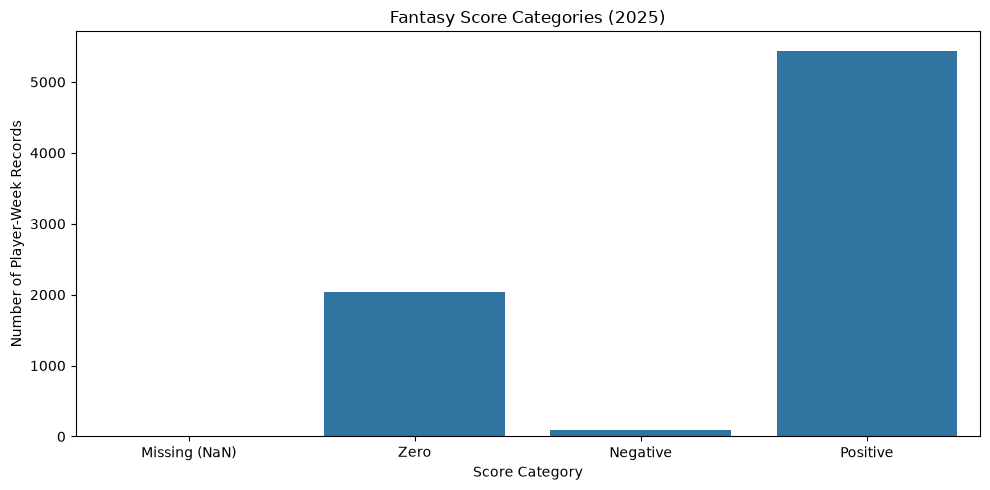

In [21]:
plt.figure(figsize=(10, 5))

order = ["Missing (NaN)", "Zero", "Negative", "Positive"]

sns.countplot(
    data=df,
    x="score_category",
    order=order
)

plt.title("Fantasy Score Categories (2025)")
plt.xlabel("Score Category")
plt.ylabel("Number of Player-Week Records")

plt.tight_layout()
plt.show()

In [22]:
# Count each score category
counts = df["score_category"].value_counts()

# Calculate percentage of total records
percentages = (
    df["score_category"].value_counts(normalize=True) * 100
).round(2)

# Combine into a table
summary = pd.DataFrame({
    "Count": counts,
    "Percentage (%)": percentages
})

display(summary)

,Count,Percentage (%)
score_category,,
Positive,5442,71.87
Zero,2043,26.98
Negative,87,1.15


### Interpretation

The dataset contains 7,572 player-week records from the 2025 NFL season. Approximately 71.87% of the records have positive fantasy scores, while 26.98% have scores of exactly zero. Only 1.15% of records have negative fantasy scores, and there are no missing values in the fantasy points column.

The relatively large proportion of zero scores suggests that some player-week observations have little or no recorded fantasy production. However, we cannot determine whether these players participated in games based on fantasy points alone.

Since there are no missing fantasy scores in this dataset, we do not need to handle missing values for this particular column. We will still investigate missing values in other features during preprocessing.

In [23]:
# Count each score category by position
position_counts = pd.crosstab(
    df["position"],
    df["score_category"]
)

# Calculate percentages within each position
position_percent = (
    position_counts.div(
        position_counts.sum(axis=1),
        axis=0
    ) * 100
).round(2)

display(position_percent)

score_category,Negative,Positive,Zero
position,,,
K,0.55,96.32,3.13
QB,6.36,89.50,4.14
RB,1.05,75.33,23.62
TE,0.17,59.34,40.48
WR,0.68,68.42,30.90


In [25]:
print("Dataset shape:", df.shape)

print("\nMissing fantasy points:")
print(df["fantasy_points"].isna().sum())

print("\nScore categories:")
print(df["score_category"].value_counts(dropna=False))

print("\nPositions:")
print(df["position"].value_counts())

Dataset shape: (7572, 82)

Missing fantasy points:
0

Score categories:
score_category
Positive    5442
Zero        2043
Negative      87
Name: count, dtype: int64

Positions:
position
WR    2806
RB    1808
TE    1739
QB     676
K      543
Name: count, dtype: int64


In [26]:
print("Projection columns:")
print([col for col in df.columns if "project" in col.lower()])

print("\nMissing values:")
print(df[["fantasy_points", "projected_points"]].isna().sum())

print("\nSummary statistics:")
display(df[["fantasy_points", "projected_points"]].describe())


Projection columns:
['projected_points']

Missing values:
fantasy_points        0
projected_points    291
dtype: int64

Summary statistics:


,fantasy_points,projected_points
count,7572.000000,7281.000000
mean,6.526960,6.948332
std,7.599769,5.911628
min,-3.060000,0.000000
25%,0.000000,1.648295
50%,3.920000,6.218530
75%,10.100000,10.808601
max,55.400000,27.880636


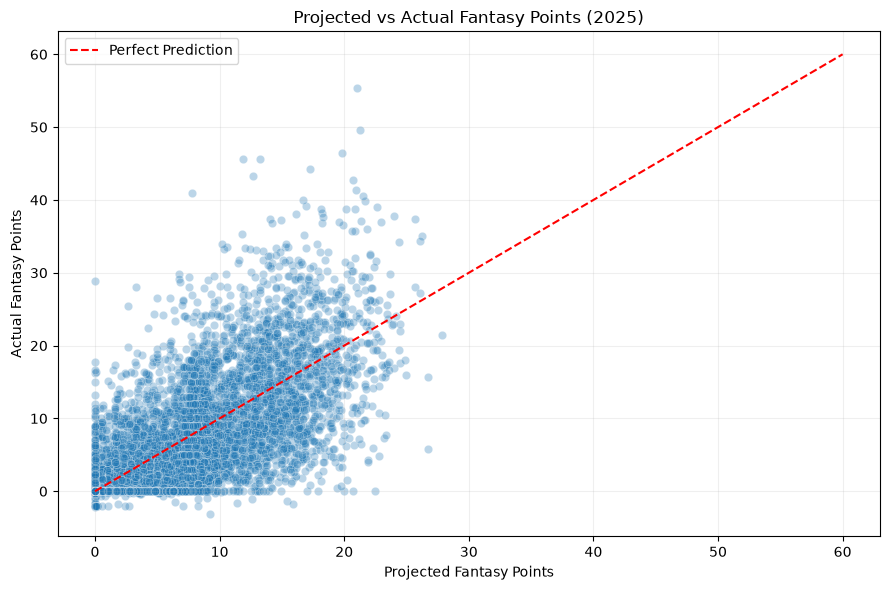

In [27]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="projected_points",
    y="fantasy_points",
    alpha=0.3
)

# Perfect prediction reference line
plt.plot(
    [0, 60],
    [0, 60],
    color="red",
    linestyle="--",
    label="Perfect Prediction"
)

plt.title("Projected vs Actual Fantasy Points (2025)")
plt.xlabel("Projected Fantasy Points")
plt.ylabel("Actual Fantasy Points")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### 2: Projected vs. Actual Fantasy Points

The scatterplot shows a positive relationship between projected and actual fantasy points. Players with higher projected scores generally tend to earn more fantasy points, but there is considerable variation in their actual performance.

The red dashed line represents a perfect prediction, where projected points equal actual points. Observations above the line indicate players who outperformed their projections, while observations below the line indicate players who underperformed.

Some players scored significantly more or less than expected, suggesting that ESPN projections do not fully capture week-to-week performance variability. This highlights the potential value of incorporating additional features into our prediction model.

In [28]:
# Compare records with available projections
comparison = df[df["projected_points"].notna()].copy()

# Actual minus projected points
comparison["error"] = (
    comparison["fantasy_points"] - comparison["projected_points"]
)

# Calculate metrics
mae = comparison["error"].abs().mean()
mean_error = comparison["error"].mean()

correlation = comparison[
    ["projected_points", "fantasy_points"]
].corr().iloc[0, 1]

print("Records compared:", len(comparison))
print("Mean Absolute Error:", round(mae, 2))
print("Mean Error:", round(mean_error, 2))
print("Correlation:", round(correlation, 3))

Records compared: 7281
Mean Absolute Error: 3.8
Mean Error: -0.18
Correlation: 0.702


### Visualization 2: Projected vs. Actual Fantasy Points

The scatterplot shows a positive relationship between ESPN's projected fantasy points and actual player performance. The correlation of 0.702 indicates that higher projected scores generally correspond to higher actual scores.

However, the Mean Absolute Error (MAE) of 3.80 shows that projections differ from actual scores by approximately 3.8 points on average. The mean error of -0.18 suggests that ESPN slightly overestimates player performance overall, although this bias is relatively small.

These results suggest that ESPN projections provide a useful baseline but still have noticeable prediction errors. Our project can investigate whether additional player statistics, matchup information, and other features could improve prediction accuracy.

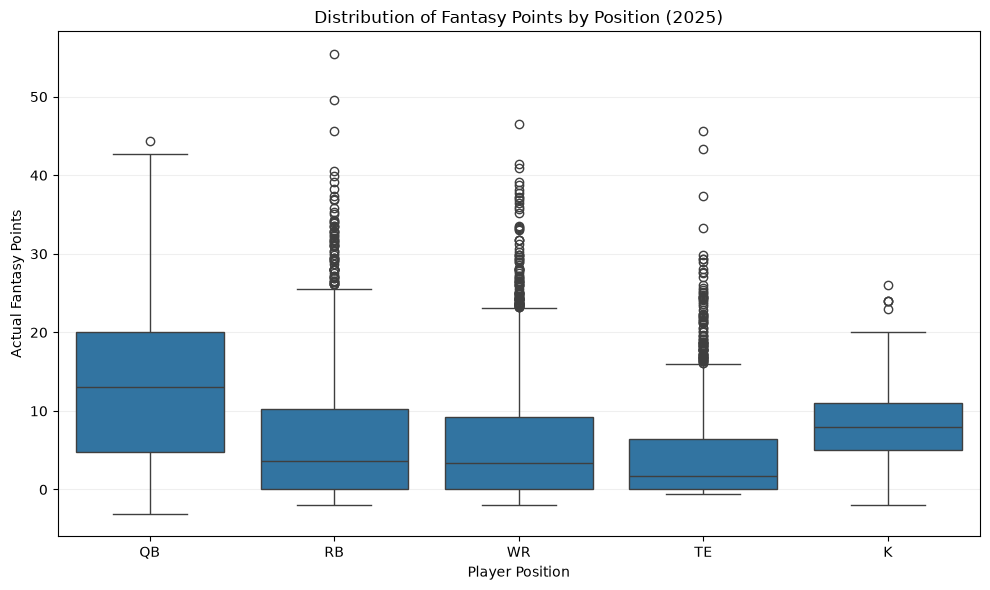

In [29]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="position",
    y="fantasy_points",
    order=["QB", "RB", "WR", "TE", "K"]
)

plt.title("Distribution of Fantasy Points by Position (2025)")
plt.xlabel("Player Position")
plt.ylabel("Actual Fantasy Points")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

### Visualization 3: Distribution of Fantasy Points by Position

The boxplot shows that fantasy point distributions vary considerably across player positions. Quarterbacks have the highest median fantasy points, around 13, while tight ends have the lowest median, around 1.5. Kickers have a median of approximately 8 points and a relatively smaller spread compared to quarterbacks.

Running backs, wide receivers, and tight ends have many high-scoring outliers, suggesting that some players occasionally perform significantly better than their typical scores.

These differences suggest that player position is an important feature when predicting fantasy performance. Our model may benefit from accounting for position-specific scoring patterns rather than treating all players the same.

In [30]:
position_stats = (
    df.groupby("position")["fantasy_points"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

display(position_stats)

,count,mean,median,std,min,max
position,,,,,,
K,543,8.27,8.00,4.80,-2.00,26.0
QB,676,13.11,13.11,9.48,-3.06,44.3
RB,1808,6.67,3.60,8.07,-2.00,55.4
TE,1739,4.16,1.70,5.81,-0.60,45.6
WR,2806,5.97,3.40,7.22,-2.00,46.5


### Visualization 3: Distribution of Fantasy Points by Position

The boxplot shows clear differences in fantasy scoring across player positions. Quarterbacks have the highest average and median fantasy points (13.11), while tight ends have the lowest median (1.70). Kickers have a median of 8.00 and a relatively smaller standard deviation of 4.80.

Running backs and wide receivers show right-skewed distributions, with means higher than their medians and several high-scoring outliers. Quarterbacks have the highest standard deviation (9.48), indicating substantial variation in their weekly scores.

These findings suggest that player position is an important feature for fantasy point prediction, and position-specific scoring patterns should be considered during modeling.

In [31]:
print([col for col in df.columns if "week" in col.lower()])

['week']


,week,mean,median,count
0,1,6.228412,3.60,447
1,2,6.963221,4.60,447
2,3,6.277360,4.00,447
3,4,6.735865,3.90,445
4,5,7.147121,4.00,396
5,6,6.516852,4.40,413
6,7,6.583405,3.70,417
7,8,6.911989,4.30,362
8,9,6.824821,3.95,390
9,10,6.365013,3.30,391


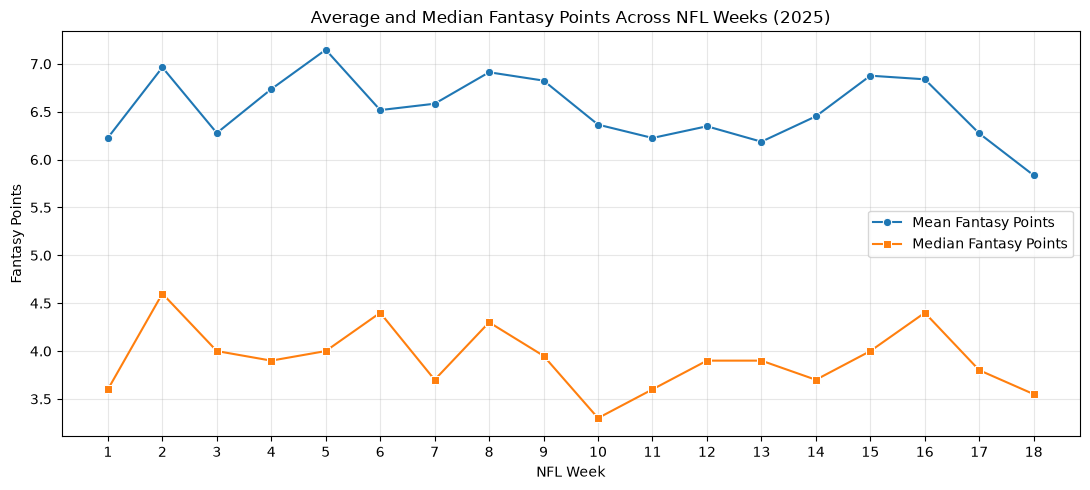

In [32]:
weekly_scores = (
    df.groupby("week")["fantasy_points"]
    .agg(["mean", "median", "count"])
    .reset_index()
)

display(weekly_scores)

plt.figure(figsize=(11, 5))

sns.lineplot(
    data=weekly_scores,
    x="week",
    y="mean",
    marker="o",
    label="Mean Fantasy Points"
)

sns.lineplot(
    data=weekly_scores,
    x="week",
    y="median",
    marker="s",
    label="Median Fantasy Points"
)

plt.title("Average and Median Fantasy Points Across NFL Weeks (2025)")
plt.xlabel("NFL Week")
plt.ylabel("Fantasy Points")
plt.xticks(sorted(weekly_scores["week"].unique()))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Visualization 4: Average and Median Fantasy Points Across NFL Weeks

The line chart shows that average fantasy points remain relatively stable throughout the 2025 NFL season, generally ranging between 6 and 7 points per player-week. The highest average occurs around Week 5, while Week 18 has the lowest average.

The median fluctuates between approximately 3.3 and 4.6 points and remains consistently below the mean. This suggests that fantasy scoring is right-skewed, with some high-scoring performances increasing the overall average.

Although weekly scoring does not show a strong increasing or decreasing trend, there are noticeable fluctuations. This suggests that NFL week may be worth investigating as a potential feature, although changes in player participation and the composition of the dataset could also explain these patterns.

,position,absolute_error
0,QB,5.545253
1,WR,3.893470
2,K,3.818751
3,RB,3.811942
4,TE,2.912878


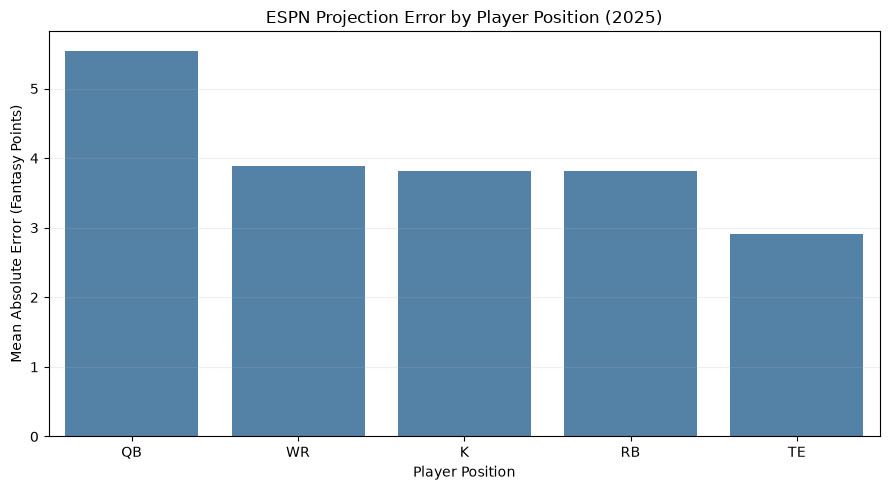

In [33]:
# Calculate absolute projection error for each player-week
comparison["absolute_error"] = comparison["error"].abs()

# Average absolute error by position
position_mae = (
    comparison.groupby("position")["absolute_error"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

display(position_mae)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=position_mae,
    x="position",
    y="absolute_error",
    color="steelblue"
)

plt.title("ESPN Projection Error by Player Position (2025)")
plt.xlabel("Player Position")
plt.ylabel("Mean Absolute Error (Fantasy Points)")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

### Visualization 5: ESPN Projection Error by Player Position

The bar chart compares ESPN's Mean Absolute Error (MAE) across different player positions. Quarterbacks have the highest average prediction error at approximately 5.55 fantasy points, while tight ends have the lowest at approximately 2.91 points. Running backs, wide receivers, and kickers have relatively similar prediction errors, ranging from about 3.8 to 3.9 points.

These results suggest that ESPN's projection accuracy varies depending on player position. However, positions also have different scoring distributions, so higher absolute errors do not necessarily indicate worse relative prediction performance.

This finding is relevant to our project because incorporating position-specific features or evaluating models separately by position may help us better understand and improve fantasy point predictions.

performance_type,Boom,Near Projection,Bust
position,,,
K,16.94,70.53,12.52
QB,20.21,55.47,24.32
RB,13.11,71.17,15.72
TE,11.60,81.07,7.33
WR,12.91,70.68,16.41


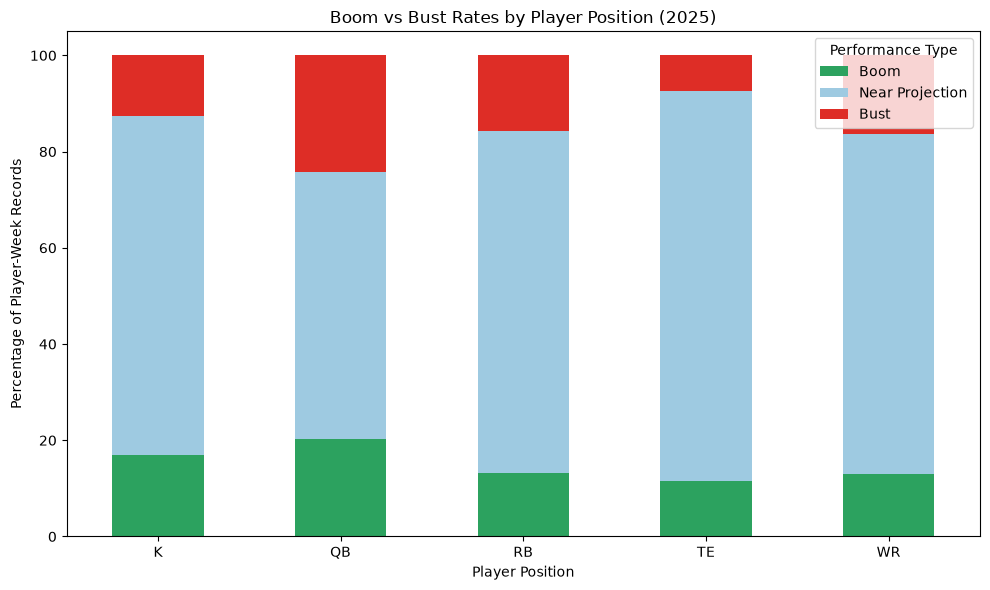

In [34]:
comparison["performance_type"] = np.select(
    [
        comparison["error"] >= 5,
        comparison["error"] <= -5
    ],
    ["Boom", "Bust"],
    default="Near Projection"
)

boom_bust = pd.crosstab(
    comparison["position"],
    comparison["performance_type"],
    normalize="index"
) * 100

boom_bust = boom_bust.reindex(
    columns=["Boom", "Near Projection", "Bust"],
    fill_value=0
)

display(boom_bust.round(2))

boom_bust.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6),
    color=["#2ca25f", "#9ecae1", "#de2d26"]
)

plt.title("Boom vs Bust Rates by Player Position (2025)")
plt.xlabel("Player Position")
plt.ylabel("Percentage of Player-Week Records")
plt.xticks(rotation=0)
plt.legend(title="Performance Type")
plt.tight_layout()
plt.show()

### Visualization 6: Boom vs. Bust Rates by Player Position

The stacked bar chart compares how frequently players outperform or underperform ESPN's fantasy projections by at least five points. Quarterbacks have the highest boom and bust rates, with approximately 20% of performances exceeding projections by five or more points and 24% falling below projections by at least five points.

Tight ends have the highest percentage of performances near their projections, at approximately 81%. Running backs and wide receivers show similar distributions, with most performances falling within five points of their projected scores.

These findings suggest that projection errors vary across positions. However, since quarterbacks typically score more points, a fixed five-point threshold may exaggerate their boom and bust rates relative to lower-scoring positions. Future analysis could use position-specific or normalized thresholds.

In [35]:
location_columns = [
    col for col in df.columns
    if any(
        word in col.lower()
        for word in ["home", "away", "location", "atvs", "venue"]
    )
]

print(location_columns)

for col in location_columns:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False).head(10))

['atVs', 'location']

atVs:
atVs
home    3904
away    3668
Name: count, dtype: int64

location:
location
Inglewood, CA          469
East Rutherford, NJ    464
Kansas City, MO        266
Denver, CO             265
Baltimore, MD          259
Minneapolis, MN        257
Nashville, TN          251
Houston, TX            250
Cincinnati, OH         249
Orchard Park, NY       248
Name: count, dtype: int64


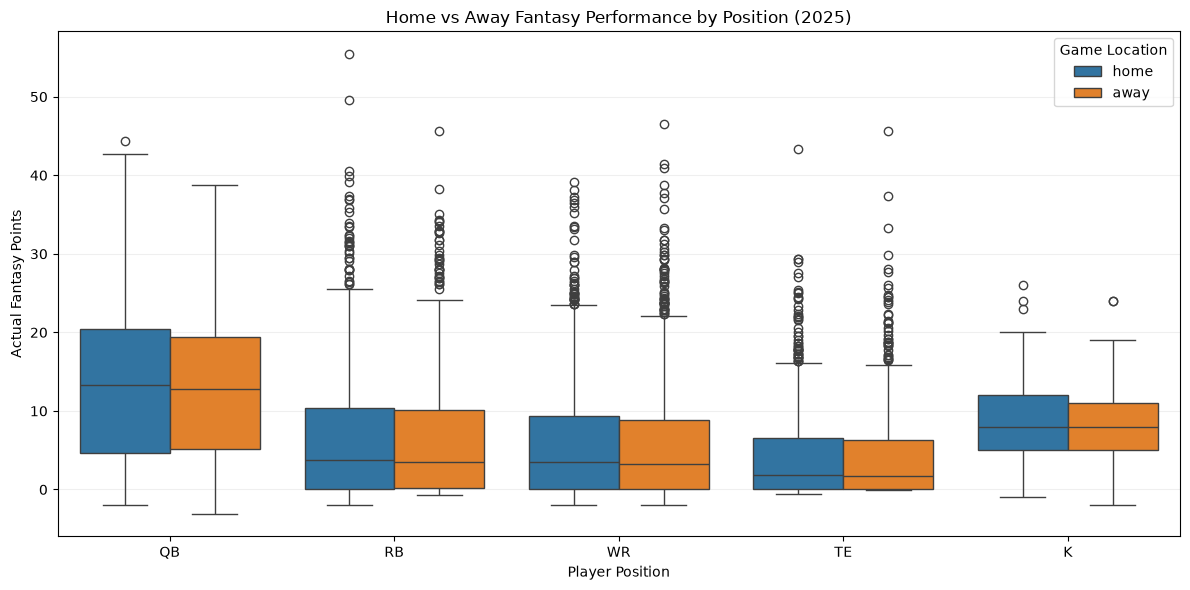

In [36]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="position",
    y="fantasy_points",
    hue="atVs",
    order=["QB", "RB", "WR", "TE", "K"],
    hue_order=["home", "away"]
)

plt.title("Home vs Away Fantasy Performance by Position (2025)")
plt.xlabel("Player Position")
plt.ylabel("Actual Fantasy Points")
plt.legend(title="Game Location")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

### Visualization 7: Home vs. Away Fantasy Performance by Position

The boxplot compares fantasy points scored by players during home and away games across five positions: QB, RB, WR, TE, and K.

Overall, the distributions appear relatively similar between home and away games. Quarterbacks have nearly identical median scores in both settings, while running backs, wide receivers, tight ends, and kickers also show considerable overlap between their home and away distributions.

These findings suggest that home-field advantage may not have a strong overall relationship with fantasy scoring in this dataset. However, game location could still be useful when combined with other factors such as opponent strength, player position, and individual player performance.

In [37]:
home_away_stats = (
    df.groupby(["position", "atVs"])["fantasy_points"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

display(home_away_stats)

count   mean  median   std
position atVs                            
K        away    264   7.91    8.00  4.70
         home    279   8.60    8.00  4.87
QB       away    324  12.97   12.77  9.03
         home    352  13.24   13.24  9.88
RB       away    879   6.53    3.50  7.82
         home    929   6.82    3.70  8.29
TE       away    843   4.20    1.70  5.91
         home    896   4.13    1.80  5.73
WR       away   1358   5.88    3.30  7.30
         home   1448   6.06    3.50  7.15

### Visualization 7: Home vs. Away Fantasy Performance by Position

The boxplot compares fantasy points scored during home and away games across five player positions. Overall, the scoring distributions are relatively similar, with substantial overlap between home and away performances.

Kickers show the largest difference in average fantasy points, scoring 8.60 points at home compared to 7.91 away. Quarterbacks, running backs, and wide receivers also have slightly higher home averages, while tight ends score marginally more away.

These results suggest that home-field advantage may have a small relationship with fantasy scoring, but the differences are not large enough to establish a strong effect from this analysis alone. Game location could still be useful as a predictive feature when combined with player statistics, opponent strength, and other matchup-related variables.